# Chapter 13 · Classification with scikit-learn

Before building the Spark ML pipeline, we solve the same problem with **scikit-learn**, Python's
single-machine machine learning library: predict whether a recipe is a **dessert** from the
cleaned data of Part 1. Each step has a Spark counterpart, which we use in the Part 2 notebook:

| Step | scikit-learn | Spark ML |
|---|---|---|
| Fill missing values | `SimpleImputer` | `Imputer` |
| Scale to 0–1 | `MinMaxScaler` | `MinMaxScaler` |
| Put the feature columns together | `ColumnTransformer` | `VectorAssembler` |
| Chain the steps | `Pipeline` | `Pipeline` |
| Classifier | `LogisticRegression` | `LogisticRegression` |
| Tune hyperparameters with cross-validation | `GridSearchCV` | `ParamGridBuilder` + `CrossValidator` |
| Evaluate | `classification_report`, `roc_auc_score` | `BinaryClassificationEvaluator` |

The big difference: scikit-learn needs the whole data set in one machine's memory as a pandas
data frame. That is fine for 20,000 recipes; Spark is what you use when the data does not fit.

# Create a spark session
Spark is used only to read the cleaned recipes from Part 1.

In [1]:
import sys
from pyspark.sql import SparkSession
from pyspark.sql.utils import AnalysisException
import pyspark.sql.functions as F
import pyspark.sql.types as T
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# change the account name to your email account
account='sli'

# define a root path to access the data in the DataAnalysisWithPythonAndPySpark
data_path='/net/clusterhn/home/'+account+'/isa460/data/'

# append path to helper_functions to system path
sys.path.append('/net/clusterhn/home/sli/isa460')

import os
os.environ["PYSPARK_PYTHON"] = "/opt/conda/envs/BigDataEnv/bin/python3.12"
os.environ["PYSPARK_DRIVER_PYTHON"] = "/opt/conda/envs/BigDataEnv/bin/python3.12"

import helper_functions as H

# check if the Spark session is active. If it is activate, close it

try:
    if spark:
        spark.stop()
except:
    pass    

spark = (SparkSession.builder.appName("Preparing Featurers for Machine Learning")
        .config("spark.port.maxRetries", "200")
        .config("spark.sql.mapKeyDedupPolicy", "LAST_WIN")  # This configuration allow the duplicate keys in the map data type.
        .config("spark.driver.memory", "8g")
        .getOrCreate())

# confiture the log level (defaulty is WARN)
spark.sparkContext.setLogLevel('ERROR')

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/25 10:46:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/25 10:46:09 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/25 10:46:09 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


## Load the cleaned recipes into pandas

In [2]:
# toPandas() collects every row onto the driver. Fine for ~20,000 recipes,
# but this is exactly the step that fails when the data is truly big.
food_pd = spark.read.parquet(data_path+'recipes/recipes_cleaned').toPandas()

CONTINUOUS = ["rating", "calories", "protein", "fat", "sodium"]
RATIOS = ["protein_ratio", "fat_ratio"]
TARGET = "dessert"
BINARY = [c for c in food_pd.columns if c not in CONTINUOUS + RATIOS + [TARGET, "title"]]

X = food_pd[CONTINUOUS + RATIOS + BINARY]
y = food_pd[TARGET].astype(int)

print("rows, features:", X.shape)
print("share of desserts:", round(y.mean(), 3))
print("missing values in the continuous columns:")
print(X[CONTINUOUS].isna().sum())

rows, features: (20049, 513)
share of desserts: 0.178
missing values in the continuous columns:
rating         1
calories    4117
protein     4161
fat         4183
sodium      4119
dtype: int64


## Build the pipeline

Continuous columns are imputed with the mean and scaled to 0–1; the two ratios and the binary
columns go in as they are, just like the Spark pipeline. Because the imputer and scaler sit
inside the pipeline, they learn their means and min/max from the **training data only**.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 70% train, 30% test, as in the Spark notebook
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=13, stratify=y)

preprocess = ColumnTransformer([
    ("continuous", Pipeline([("impute", SimpleImputer(strategy="mean")),
                             ("scale", MinMaxScaler())]), CONTINUOUS),
    ("as_is", "passthrough", RATIOS + BINARY),
])

sk_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=1000)),
])

## Tune the hyperparameters with cross-validation

In [4]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__penalty": ["l2", "l1"],  # Spark: elasticNetParam 0.0 (L2) and 1.0 (L1)
    "classifier__C": [0.1, 1, 10],        # smaller C = stronger regularization (Spark: larger regParam)
    "classifier__solver": ["liblinear"],  # a solver that handles both l1 and l2
}

# n_jobs=4 runs four fits at a time; -1 would take every core on the shared HPC node
grid = GridSearchCV(sk_pipeline, param_grid, cv=5, scoring="roc_auc", n_jobs=4)
grid.fit(X_train, y_train)

print("Best hyperparameters:", grid.best_params_)
print("Best cross-validated area under ROC:", round(grid.best_score_, 4))

Best hyperparameters: {'classifier__C': 1, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Best cross-validated area under ROC: 0.9936


## Evaluate on the test set

In [5]:
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, RocCurveDisplay)

y_pred = grid.predict(X_test)               # uses the best model found above
y_prob = grid.predict_proba(X_test)[:, 1]   # probability of being a dessert

print("Confusion matrix:")
print(pd.DataFrame(confusion_matrix(y_test, y_pred),
                   index=["actual 0", "actual 1"], columns=["predicted 0", "predicted 1"]))
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Area under ROC:", round(roc_auc_score(y_test, y_prob), 4))
print("\n", classification_report(y_test, y_pred))

Confusion matrix:
          predicted 0  predicted 1
actual 0         4889           54
actual 1           94          978

Accuracy: 0.9754
Area under ROC: 0.9921

               precision    recall  f1-score   support

           0       0.98      0.99      0.99      4943
           1       0.95      0.91      0.93      1072

    accuracy                           0.98      6015
   macro avg       0.96      0.95      0.96      6015
weighted avg       0.98      0.98      0.98      6015



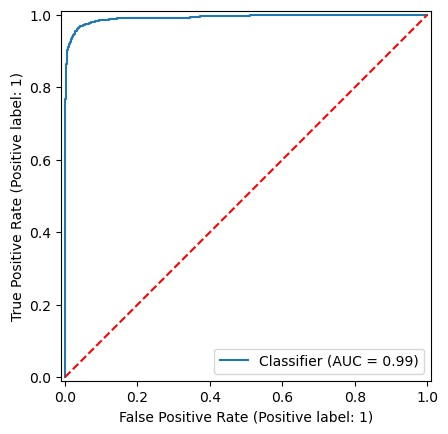

In [6]:
# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], "r--")
plt.show()

## The biggest drivers: the coefficients

In [7]:
best = grid.best_estimator_
names = best.named_steps["preprocess"].get_feature_names_out()

coefficients = pd.DataFrame({"coef": best.named_steps["classifier"].coef_[0]}, index=names)
coefficients.index = coefficients.index.str.replace(r"^(continuous|as_is)__", "", regex=True)
coefficients["abs_coef"] = coefficients["coef"].abs()

print(coefficients.sort_values("abs_coef", ascending=False).head(20))

                      coef  abs_coef
side             -5.171132  5.171132
appetizer        -3.807270  3.807270
protein_ratio    -3.377245  3.377245
dinner           -2.776519  2.776519
breakfast        -2.706617  2.706617
condiment_spread -2.312743  2.312743
fish             -2.062625  2.062625
chicken          -2.011359  2.011359
bread            -1.995041  1.995041
drink            -1.951796  1.951796
protein          -1.934084  1.934084
cocktail_party   -1.908643  1.908643
onion            -1.862064  1.862064
cocktail         -1.858845  1.858845
alcoholic        -1.795065  1.795065
tomato           -1.777676  1.777676
pork             -1.742550  1.742550
soup_stew        -1.740071  1.740071
pie               1.688730  1.688730
leafy_green      -1.664046  1.664046


# Summary

- scikit-learn and Spark ML share the same ideas: transformers, estimators with `fit()`, pipelines,
  and a grid search with cross-validation.
- The pipeline keeps preprocessing honest: the imputer and scaler learn only from the training data.
- scikit-learn works on a pandas data frame in one machine's memory; Spark ML runs the same steps on
  data spread across a cluster.

Keep these results in mind for the Part 2 notebook, and compare the accuracy, area under ROC and
top coefficients. Spark's `LogisticRegression` uses **no regularization by default**
(`regParam = 0`), so its grid also tries `regParam` values; scikit-learn's applies L2
regularization with `C = 1` unless told otherwise.

In [8]:
spark.stop()